# 04 · Tracking and the Final Video

This is where everything comes together:

```
frame ──► Faster R-CNN ──► boxes ──► Siamese Re-ID ──► embeddings ──► Tracker ──► IDs
                                                                     (Kalman + Hungarian
                                                                      + gating + offline rules)
```

Steps:
1. Run the detector and the Re-ID network once over MOT16-09 (validation) and MOT16-01 (test), and cache the results on Drive
2. Track MOT16-09, where we have ground truth, and measure the result
3. Track MOT16-01, follow our target pedestrian, and render the submission videos
4. Measure speed (FPS) for the self-evaluation section

Needs notebooks 02 and 03 to be finished (it loads both models). Runtime: **T4 GPU**. About 15 minutes the first time, about 5 minutes afterwards (the detections are cached; most of the time goes into writing the videos).

In [1]:
# ---- Setup (identical in every notebook) -----------------------------------
# The ONLY line you may need to change: where the project folder sits on your Drive.
# If a teammate shared the folder with you, right-click it in Drive ->
# "Organize" -> "Add shortcut" -> My Drive, and this path will work unchanged.
PROJECT_DIR = "/content/drive/MyDrive/DL_Project_MOT"

from google.colab import drive
drive.mount("/content/drive")

import os, sys
assert os.path.isdir(os.path.join(PROJECT_DIR, "src")), (
    f"Can't find {PROJECT_DIR}/src. Upload the project folder to Drive first (see README).")
sys.path.insert(0, os.path.join(PROJECT_DIR, "src"))

import config
paths = config.get_paths(PROJECT_DIR)

import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU (switch the runtime to T4 GPU!)")

Mounted at /content/drive
Device: Tesla T4


In [2]:
import json, time
import numpy as np
import pandas as pd
from mot_data import prepare_mot16, parse_gt, parse_ignore_regions, read_seqinfo
from detector import load_pedestrian_detector
from reid import load_reid
from pipeline import process_sequence
from tracker import TrackerConfig, run_tracker, save_mot, track_lengths
from metrics import evaluate_tracking
from viz import render_tracks, show_video, target_filmstrip

MOT_ROOT = prepare_mot16(paths)
val_dir = f"{MOT_ROOT}/train/{config.VAL_SEQ}"
test_dir = f"{MOT_ROOT}/test/{config.TEST_SEQ}"
vi, ti = read_seqinfo(val_dir), read_seqinfo(test_dir)
VAL_SIZE, TEST_SIZE = (vi["width"], vi["height"]), (ti["width"], ti["height"])

det_model = load_pedestrian_detector(paths.detector_ckpt, device)
reid_model = load_reid(paths.reid_ckpt, device)
print("Both models loaded.")

Unzipping MOT16.zip to /content/MOT16 ...
MOT16 ready at /content/MOT16
Both models loaded.


## 1. Detection + Re-ID for every frame (cached)

We keep every box with confidence ≥ 0.3 here; the tracker decides which ones it uses.
The result is cached in `outputs/detections/`, so the tracking below (and all experiments in notebook 05) take seconds instead of minutes. On a second run this cell just loads the cache.

In [3]:
val_data = process_sequence(det_model, reid_model, val_dir, device, score_thresh=0.3,
                            cache_path=f"{paths.detections}/{config.VAL_SEQ}_finetuned.pkl")
test_data = process_sequence(det_model, reid_model, test_dir, device, score_thresh=0.3,
                             cache_path=f"{paths.detections}/{config.TEST_SEQ}_finetuned.pkl")
for name, d in [(config.VAL_SEQ, val_data), (config.TEST_SEQ, test_data)]:
    t = d["timing"]
    print(f"{name}: {t['frames']} frames | detector {t['detector_fps']:.1f} FPS | "
          f"Re-ID {t['reid_fps']:.1f} FPS | {t['boxes_per_frame']:.1f} boxes/frame")

Loaded cached detections: MOT16-09_finetuned.pkl
Loaded cached detections: MOT16-01_finetuned.pkl
MOT16-09: 525 frames | detector 9.0 FPS | Re-ID 103.9 FPS | 13.7 boxes/frame
MOT16-01: 450 frames | detector 9.6 FPS | Re-ID 96.0 FPS | 21.4 boxes/frame


## 2. Tracker settings and how we chose them

The tracker's first settings gave too many identity switches. We measured one change at a time on MOT16-09 (which has ground truth) and inspected the target in MOT16-01 with filmstrips. The path we took:

| Step | Change | MOTA | IDF1 | ID switches |
|---|---|---|---|---|
| 1 | First settings (start threshold 0.6, low-score pass from 0.3, interpolation up to 40 frames) | 37.7 | 49.9 | 76 |
| 2 | Start threshold 0.7, low-score pass off, interpolation off | 56.0 | 53.4 | 46 |
| 3 | Low-score pass back on, but only for boxes scoring 0.6–0.7 (keeps the target alive while he turns and leaves) | 55.1 | 51.1 | 47 |
| 4 | Offline rule: a track that disappears at the image border has left; anything that later continues it is a new person | 55.1 | 54.9 | 47 |

Lessons (also in the report's *Challenges* section):
* Long interpolation added ~900 false boxes: after a wrong re-attachment it filled the gap between two *different* people. Interpolation is now limited to drop-outs of ≤ 5 frames.
* Accepting very low-confidence boxes kept wrong tracks alive; accepting only 0.6–0.7 keeps the useful part.
* The target was always lost the moment he left the picture and his old ID then latched onto a newcomer; the exit rule fixes this for every track, not just him.

These final settings are the defaults in `src/tracker.py` (every parameter is commented there). The appearance threshold comes from the Re-ID validation in notebook 03.

In [4]:
cfg = TrackerConfig()
# Appearance threshold: notebook 03's histogram gave 0.343 as the best split for
# *random* pairs of people, but the tracker has to separate nearby, similar-looking
# people. The parameter study in notebook 05 showed a stricter threshold works much
# better (IDF1 54.8 -> 60.3, ID switches 46 -> 35 on MOT16-09), and the target in
# MOT16-01 is still tracked in all 361 frames. Note: chosen on MOT16-09 itself.
cfg.app_thresh = 0.15
print("Appearance threshold (cosine):", cfg.app_thresh)
pd.Series(cfg.as_dict()).to_frame("value")

Appearance threshold (cosine): 0.15


,value
high_thresh,0.7
low_thresh,0.6
use_kalman,True
use_appearance,True
use_low_score,True
interpolate,True
split_at_exits,True
w_app,0.6
app_thresh,0.15
iou_strong,0.5


## 3. Result on MOT16-09 (validation, has ground truth)

* **IDF1**: how consistently each real person keeps one ID. Closest to the rubric's question.
* **IDSW**: number of times a person's ID changed. Lower is better.
* **MOTA**: mostly about detection (missed people and false boxes).
* **MT / ML**: people tracked for ≥ 80% / ≤ 20% of their time on screen.

In [5]:
val_gt, val_ignore = parse_gt(val_dir), parse_ignore_regions(val_dir)
t0 = time.time()
val_tracks = run_tracker(val_data["dets"], val_data["feats"], cfg, image_size=VAL_SIZE)
tracker_fps = len(val_data["dets"]) / (time.time() - t0)
val_metrics = evaluate_tracking(val_gt, val_tracks, val_ignore)
save_mot(val_tracks, f"{paths.results_tracks}/{config.VAL_SEQ}.txt")
print({k: val_metrics[k] for k in ["MOTA", "IDF1", "IDSW", "MT", "ML", "GT_IDs", "pred_IDs"]})

{'MOTA': 55.8, 'IDF1': np.float64(60.3), 'IDSW': 35, 'MT': 14, 'ML': 0, 'GT_IDs': 25, 'pred_IDs': 49}


In [6]:
# Validation video with all IDs (saved to Drive; open it from outputs/videos/)
render_tracks(val_dir, val_tracks, f"{paths.videos}/{config.VAL_SEQ}_tracking.mp4", title="Ours (validation)")

saved /content/drive/MyDrive/DL_Project_MOT/outputs/videos/MOT16-09_tracking.mp4


'/content/drive/MyDrive/DL_Project_MOT/outputs/videos/MOT16-09_tracking.mp4'

## 4. Track the test video (MOT16-01)

In [7]:
test_tracks = run_tracker(test_data["dets"], test_data["feats"], cfg, image_size=TEST_SIZE)
save_mot(test_tracks, f"{paths.tracks}/{config.TEST_SEQ}.txt")
save_mot(test_tracks, f"{paths.results_tracks}/{config.TEST_SEQ}.txt")
lengths = track_lengths(test_tracks)
print(f"{len(lengths)} tracks in {config.TEST_SEQ} ({test_data['timing']['frames']} frames)")
print("Longest tracks (ID: frames):", dict(list(lengths.items())[:10]))

62 tracks in MOT16-01 (450 frames)
Longest tracks (ID: frames): {13: 393, 11: 361, 24: 348, 10: 336, 12: 295, 16: 291, 23: 244, 21: 238, 32: 227, 17: 225}


### Our target pedestrian

The submission needs **at least one target pedestrian** tracked through the video; the rubric's A is *tracked in every frame without being lost*.

We follow **the man in the black cardigan with a yellow scarf** who carries a white plastic bag. He is a good, demanding target: he enters at the back of the square in the first frame, walks through the crowd towards the camera for about 12 seconds (his box grows from about 120 to 460 px tall), and leaves on the right edge around frame 361.

IDs are renumbered on every run, so instead of hard-coding an ID we pick **the track that starts at his position in frame 1** (box centre near x = 486, y = 520). The filmstrip below is the check: every crop must show the same man.

Target = ID 11 | frames 1-361 | 361 frames with a box | missing frames inside the track: 0


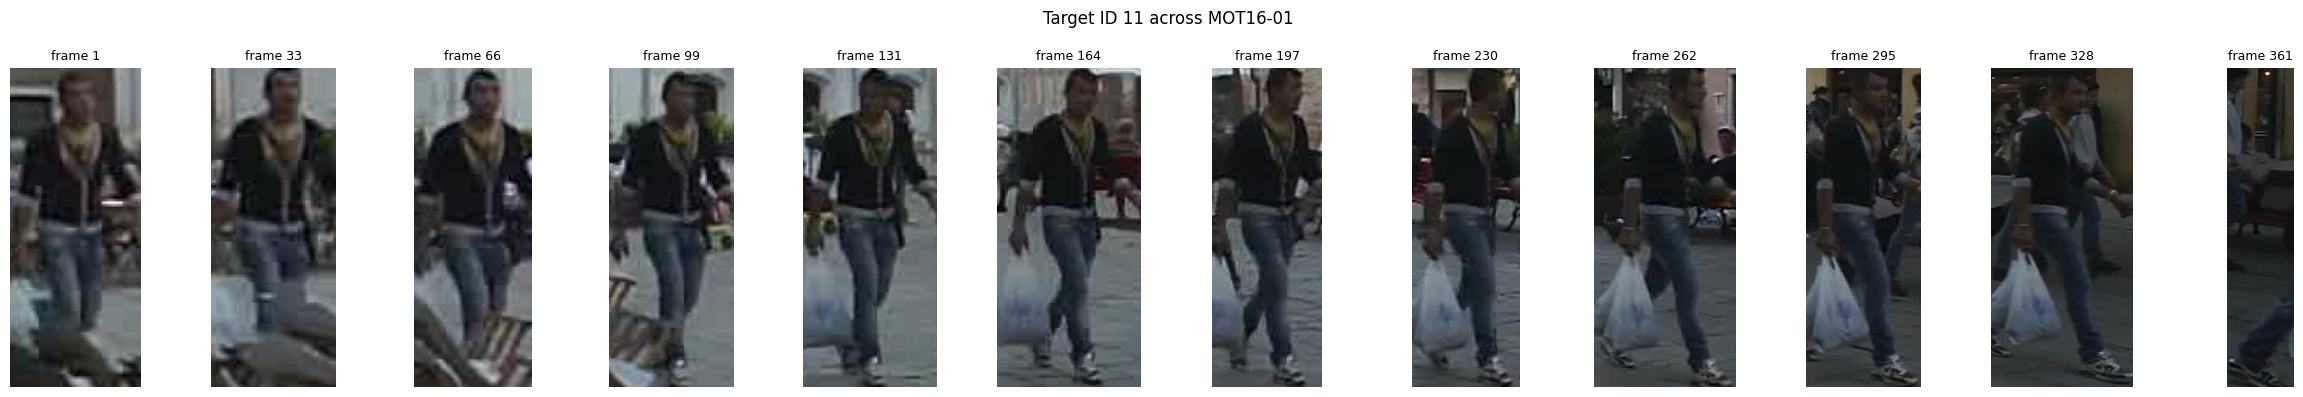

In [8]:
TARGET_POINT = (486, 520)     # where the man in the black cardigan stands in frame 1

first = test_tracks[1]
centres = np.c_[(first[:, 1] + first[:, 3]) / 2, (first[:, 2] + first[:, 4]) / 2]
TARGET_ID = int(first[np.argmin(np.linalg.norm(centres - np.array(TARGET_POINT), axis=1)), 0])

frames = [f for f in sorted(test_tracks) if TARGET_ID in test_tracks[f][:, 0].astype(int)]
gaps = [(a, b) for a, b in zip(frames[:-1], frames[1:]) if b - a > 1]
print(f"Target = ID {TARGET_ID} | frames {frames[0]}-{frames[-1]} | {len(frames)} frames with a box | "
      f"missing frames inside the track: {sum(b - a - 1 for a, b in gaps)}")

target_filmstrip(test_dir, test_tracks, TARGET_ID, n=12, out_path=f"{paths.figures}/target_filmstrip.jpg");

## 5. Final submission videos (full resolution)

* `MOT16-01_target.mp4`: the target in a thick red box with his walking trail, everyone else in thin grey. This is the required single-target video.
* `MOT16-01_all_tracks.mp4`: every tracked person in their own colour. Shows that the system tracks the whole crowd.

In [9]:
render_tracks(test_dir, test_tracks, f"{paths.videos}/{config.TEST_SEQ}_target.mp4",
              highlight_id=TARGET_ID, title="MOT16-01 single-target tracking")
render_tracks(test_dir, test_tracks, f"{paths.videos}/{config.TEST_SEQ}_all_tracks.mp4",
              title="MOT16-01 multi-object tracking")

saved /content/drive/MyDrive/DL_Project_MOT/outputs/videos/MOT16-01_target.mp4 (target visible in 361 frames)
saved /content/drive/MyDrive/DL_Project_MOT/outputs/videos/MOT16-01_all_tracks.mp4


'/content/drive/MyDrive/DL_Project_MOT/outputs/videos/MOT16-01_all_tracks.mp4'

## 6. Speed (for the self-evaluation section)

In [10]:
t = test_data["timing"]
total_ms = 1000 / t["detector_fps"] + 1000 / t["reid_fps"] + 1000 / tracker_fps
speed = pd.DataFrame([
    {"Stage": "Faster R-CNN detection", "ms / frame": 1000 / t["detector_fps"], "FPS": t["detector_fps"]},
    {"Stage": "Siamese Re-ID (all boxes in a frame)", "ms / frame": 1000 / t["reid_fps"], "FPS": t["reid_fps"]},
    {"Stage": "Tracker (Kalman + Hungarian)", "ms / frame": 1000 / tracker_fps, "FPS": tracker_fps},
    {"Stage": "Total pipeline", "ms / frame": total_ms, "FPS": 1000 / total_ms},
]).round(2)
speed.to_csv(f"{paths.tables}/speed.csv", index=False)

# Notebook 05 reads the exact settings and target from this file
json.dump({"gpu": torch.cuda.get_device_name(0) if device.type == "cuda" else "cpu",
           "target_id": int(TARGET_ID), "val_metrics": {k: float(v) for k, v in val_metrics.items()},
           "tracker_config": cfg.as_dict()},
          open(f"{paths.tables}/final_run.json", "w"), indent=2)
speed

,Stage,ms / frame,FPS
0,Faster R-CNN detection,104.17,9.60
1,Siamese Re-ID (all boxes in a frame),10.41,96.02
2,Tracker (Kalman + Hungarian),2.39,418.47
3,Total pipeline,116.97,8.55


## Done ✅  Check before submitting

* [ ] Watched `outputs/videos/MOT16-01_target.mp4` from start to end: the red box stays on the man in the black cardigan and ends when he leaves the picture
* [ ] Uploaded that video to YouTube (unlisted) or a Drive link with "anyone with the link can view", and put the link in the README and the report
* [ ] Ran notebook 05 so all report tables match these settings